# 03 · Evaluation & Testing on Unseen Data

**Purpose:** measure how good and how trustworthy the saved model's risk percentages are on data it has never seen, explain what drives them, and show the end-to-end prediction path on new fires.

**Inputs:** `models/fire_risk_model.joblib`, `data/test/test_set.csv` (34 held-out labelled fires, untouched until now), `data/processed/dev_set.csv` (only for out-of-fold calibration checks), `data/raw/test.csv` (95 unlabelled competition fires).

**Outputs:** `reports/figures/03_*.png`, `reports/test_metrics.csv`, `data/test/sample_input.csv`, `data/test/sample_predictions.csv`, `reports/submission.csv`.

## Setup

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")

from src.data import horizon_labels, HORIZONS, ID_COL, TIME_COL, EVENT_COL, TARGET_COLS
from src.model import horizon_scores, neg_mean_brier, concordance_index, risk_band, RISK_BANDS

DATA_DIR, FIG_DIR, REPORT_DIR = ROOT / "data", ROOT / "reports" / "figures", ROOT / "reports"
RANDOM_STATE = 42
H_COLORS = {12: "#E45756", 24: "#F2A541", 48: "#54A24B", 72: "#4C78A8"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

bundle = joblib.load(ROOT / "models" / "fire_risk_model.joblib")
model, FEATURES = bundle["model"], bundle["feature_columns"]
print({k: v for k, v in bundle.items() if k not in ("model", "feature_columns")})

{'horizons': [12, 24, 48, 72], 'model_family': 'RandomForest', 'best_params': {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 500}, 'cv_mean_brier': 0.021277736023780778, 'cv_mean_auc': 0.9924915306596341, 'cv_c_index': 0.9521480723886843, 'n_train_rows': 187, 'sklearn_version': '1.9.1', 'random_state': 42}


## 1. Load the untouched test set and predict
This is the first time `test_set.csv` is read since notebook 02 wrote it.

In [2]:
test = pd.read_csv(DATA_DIR / "test" / "test_set.csv")
X_test, y_test = test[FEATURES], test[TARGET_COLS].to_numpy()
Y = horizon_labels(test[TIME_COL], test[EVENT_COL])
P = pd.DataFrame(model.predict_proba(X_test), columns=[f"p_{h}h" for h in HORIZONS])
print(f"test rows: {len(test)} | hits: {int(test[EVENT_COL].sum())} | positives per horizon:", Y.sum().to_dict())
assert (np.diff(P.to_numpy(), axis=1) >= -1e-12).all(), "probabilities must be non-decreasing in horizon"

test rows: 34 | hits: 11 | positives per horizon: {'hit_12h': 8, 'hit_24h': 10, 'hit_48h': 11, 'hit_72h': 11}


## 2. Classification metrics per horizon
Threshold metrics use a 0.5 cut-off. Because the test set is tiny (34 fires, 8–11 positives), each ROC-AUC and Brier score comes with a **bootstrap 95% confidence interval** (2,000 resamples), so the uncertainty is visible.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(test), len(test)) for _ in range(2000)]

def boot_ci(fn, y, p):
    vals = []
    for idx in boot_idx:
        if 0 < y[idx].sum() < len(idx): vals.append(fn(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for h in HORIZONS:
    y, p = Y[f"hit_{h}h"].to_numpy(), P[f"p_{h}h"].to_numpy(); yhat = (p >= 0.5).astype(int)
    auc_lo, auc_hi = boot_ci(roc_auc_score, y, p); b_lo, b_hi = boot_ci(brier_score_loss, y, p)
    rows.append({"horizon": f"{h}h", "positives": int(y.sum()),
                 "accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
                 "recall": recall_score(y, yhat), "f1": f1_score(y, yhat), "roc_auc": roc_auc_score(y, p),
                 "roc_auc_95ci": f"[{auc_lo:.3f}, {auc_hi:.3f}]", "pr_auc": average_precision_score(y, p),
                 "brier": brier_score_loss(y, p), "brier_95ci": f"[{b_lo:.3f}, {b_hi:.3f}]"})
metrics = pd.DataFrame(rows).set_index("horizon")
overall = horizon_scores(model, X_test, y_test)
metrics.to_csv(REPORT_DIR / "test_metrics.csv")
print(f"Overall: mean Brier = {overall['mean_brier']:.4f} | mean ROC-AUC = {overall['mean_auc']:.4f} | C-index = {overall['c_index']:.4f}")
print(f"CV (dev) for comparison: mean Brier = {bundle['cv_mean_brier']:.4f} | mean ROC-AUC = {bundle['cv_mean_auc']:.4f} | C-index = {bundle['cv_c_index']:.4f}")
metrics.round(3)

Overall: mean Brier = 0.0222 | mean ROC-AUC = 0.9843 | C-index = 0.9329
CV (dev) for comparison: mean Brier = 0.0213 | mean ROC-AUC = 0.9925 | C-index = 0.9521


,positives,accuracy,precision,recall,f1,roc_auc,roc_auc_95ci,pr_auc,brier,brier_95ci
horizon,,,,,,,,,,
12h,8,0.882,0.750,0.75,0.750,0.966,"[0.894, 1.000]",0.907,0.057,"[0.019, 0.107]"
24h,10,0.971,0.909,1.00,0.952,0.971,"[0.893, 1.000]",0.906,0.030,"[0.000, 0.089]"
48h,11,1.000,1.000,1.00,1.000,1.000,"[1.000, 1.000]",1.000,0.002,"[0.000, 0.005]"
72h,11,1.000,1.000,1.00,1.000,1.000,"[1.000, 1.000]",1.000,0.000,"[0.000, 0.000]"


### Confusion matrices (threshold 0.5)

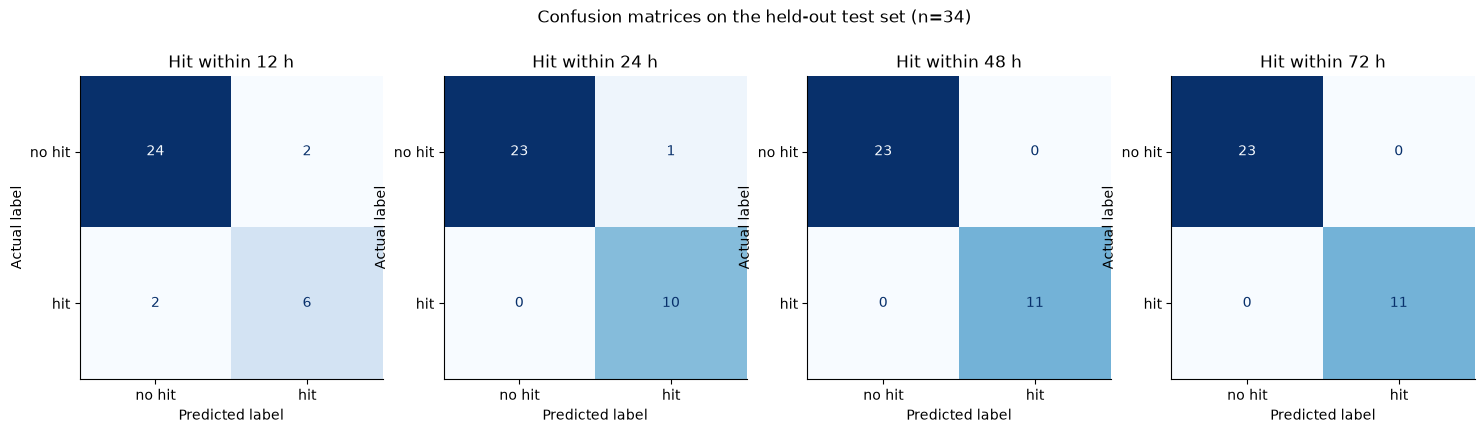

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, h in zip(axes, HORIZONS):
    cm = confusion_matrix(Y[f"hit_{h}h"], (P[f"p_{h}h"] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["no hit", "hit"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Hit within {h} h"); ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label"); ax.grid(False)
fig.suptitle(f"Confusion matrices on the held-out test set (n={len(test)})", y=1.04)
save(fig, "03_confusion_matrices"); plt.show()

### ROC and precision-recall curves

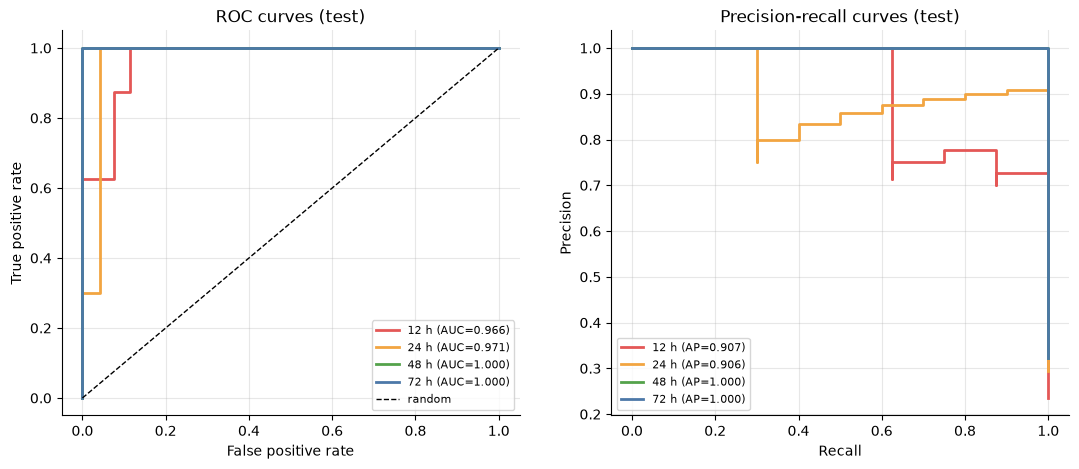

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for h in HORIZONS:
    y, p = Y[f"hit_{h}h"], P[f"p_{h}h"]
    fpr, tpr, _ = roc_curve(y, p); axes[0].plot(fpr, tpr, color=H_COLORS[h], lw=2, label=f"{h} h (AUC={roc_auc_score(y, p):.3f})")
    prec, rec, _ = precision_recall_curve(y, p); axes[1].step(rec, prec, where="post", color=H_COLORS[h], lw=2, label=f"{h} h (AP={average_precision_score(y, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curves (test)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves (test)")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
save(fig, "03_roc_pr_curves"); plt.show()

## 3. Calibration: can the risk % be trusted?
A calibrated model's 30% means about 30% of such fires actually hit. 34 test rows are too few for a reliable reliability curve, so we also show **out-of-fold predictions on the 187 development rows**. These come from the same tuned configuration refitted in 5 folds, so every prediction is for a fire the model did not see.

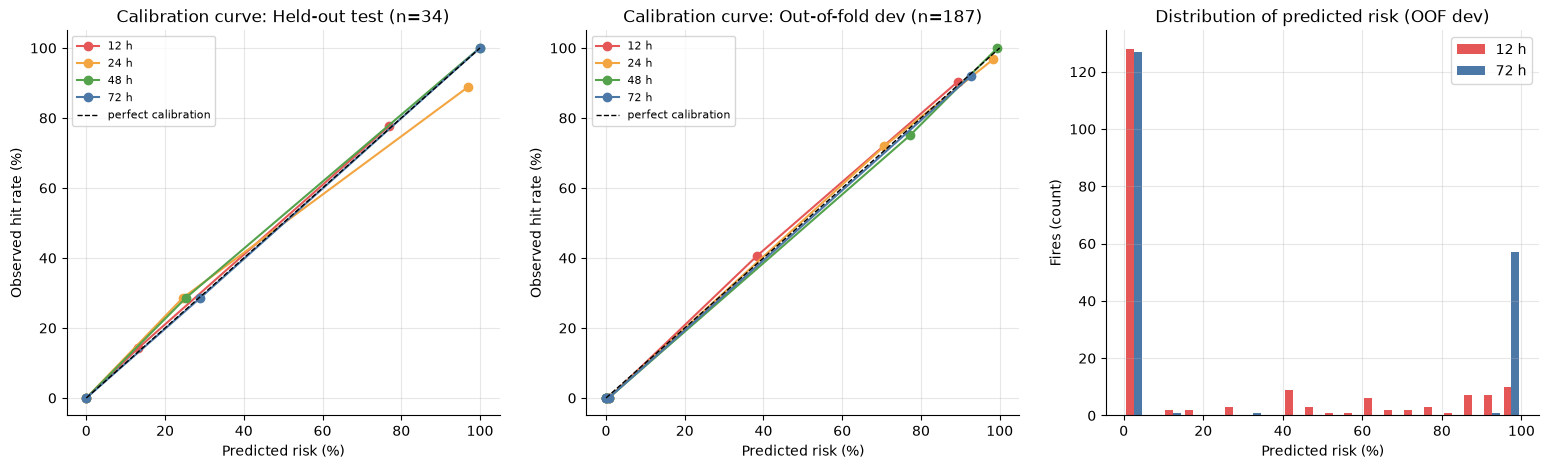

OOF Brier per horizon: {'brier_12h': 0.049, 'brier_24h': 0.0225, 'brier_48h': 0.0129, 'brier_72h': 0.0007}


In [6]:
dev = pd.read_csv(DATA_DIR / "processed" / "dev_set.csv")
Y_dev = horizon_labels(dev[TIME_COL], dev[EVENT_COL])
strata = (dev[EVENT_COL] + Y_dev["hit_12h"]).to_numpy()
oof = np.zeros((len(dev), len(HORIZONS)))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(dev, strata):
        m = clone(model).fit(dev.loc[tr, FEATURES], dev.loc[tr, TARGET_COLS].to_numpy())
        oof[va] = m.predict_proba(dev.loc[va, FEATURES])
OOF = pd.DataFrame(oof, columns=[f"p_{h}h" for h in HORIZONS])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, probs, labels, nb) in zip(axes[:2], [("Held-out test (n=34)", P, Y, 4), ("Out-of-fold dev (n=187)", OOF, Y_dev, 6)]):
    for h in HORIZONS:
        frac, mean_p = calibration_curve(labels[f"hit_{h}h"], probs[f"p_{h}h"], n_bins=nb, strategy="quantile")
        ax.plot(mean_p * 100, frac * 100, "o-", color=H_COLORS[h], label=f"{h} h")
    ax.plot([0, 100], [0, 100], "k--", lw=1, label="perfect calibration")
    ax.set_xlabel("Predicted risk (%)"); ax.set_ylabel("Observed hit rate (%)"); ax.set_title(f"Calibration curve: {name}"); ax.legend(fontsize=8)
axes[2].hist([OOF["p_12h"] * 100, OOF["p_72h"] * 100], bins=20, color=[H_COLORS[12], H_COLORS[72]], label=["12 h", "72 h"])
axes[2].set_xlabel("Predicted risk (%)"); axes[2].set_ylabel("Fires (count)"); axes[2].set_title("Distribution of predicted risk (OOF dev)"); axes[2].legend()
save(fig, "03_calibration"); plt.show()
oof_scores = {f"brier_{h}h": brier_score_loss(Y_dev[f"hit_{h}h"], OOF[f"p_{h}h"]) for h in HORIZONS}
print("OOF Brier per horizon:", {k: round(v, 4) for k, v in oof_scores.items()})

### The hard part: *when* will a fire hit?
At 72 h the distance threshold makes the task almost trivial (notebook 01). The honest test of the model is whether it can tell **early hits from late hits** *among fires that do hit*. Below we compute the ROC-AUC of `p_12h` for separating hit ≤ 12 h from hit > 12 h, using only hits. The 12 h ROC-AUC above was inflated by the many easy far-away negatives.

    test: early-vs-late AUC among hits = 0.708  (hits=11, early=8, late=3)
 OOF dev: early-vs-late AUC among hits = 0.801  (hits=58, early=41, late=17)


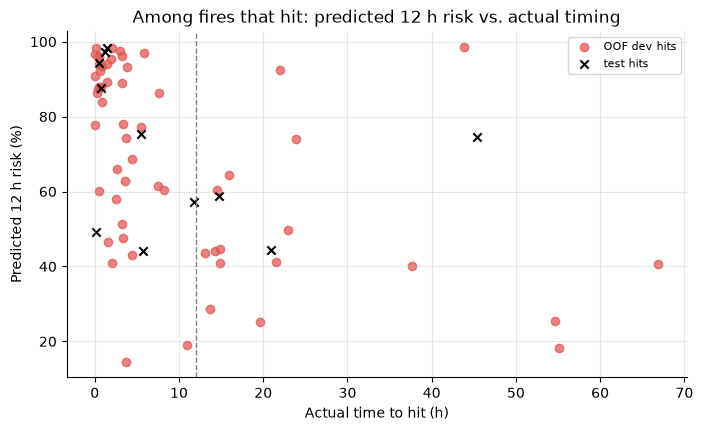

In [7]:
def timing_auc(probs, frame):
    hits = frame[EVENT_COL].to_numpy() == 1
    early = (frame.loc[hits, TIME_COL] <= 12).astype(int).to_numpy()
    return roc_auc_score(early, probs.loc[hits, "p_12h"]) if 0 < early.sum() < len(early) else np.nan, int(hits.sum()), int(early.sum())

for name, probs, frame in [("test", P, test), ("OOF dev", OOF, dev)]:
    auc, n_hits, n_early = timing_auc(probs, frame)
    print(f"{name:>8}: early-vs-late AUC among hits = {auc:.3f}  (hits={n_hits}, early={n_early}, late={n_hits - n_early})")

fig, ax = plt.subplots(figsize=(8, 4.5))
hits = dev[EVENT_COL] == 1
ax.scatter(dev.loc[hits, TIME_COL], OOF.loc[hits, "p_12h"] * 100, color=H_COLORS[12], alpha=.75, label="OOF dev hits")
th = test[EVENT_COL] == 1
ax.scatter(test.loc[th, TIME_COL], P.loc[th, "p_12h"] * 100, color="k", marker="x", label="test hits")
ax.axvline(12, color="grey", ls="--", lw=1); ax.set_xlabel("Actual time to hit (h)"); ax.set_ylabel("Predicted 12 h risk (%)")
ax.set_title("Among fires that hit: predicted 12 h risk vs. actual timing"); ax.legend(fontsize=8)
save(fig, "03_timing_among_hits"); plt.show()

## 4. Feature importance (permutation, test set)
Each input column is shuffled 30 times, and we record how much the **mean Brier score worsens**. The columns are the raw inputs, so the engineered features are recomputed from the shuffled values inside the pipeline, and a raw column gets credit for everything derived from it.

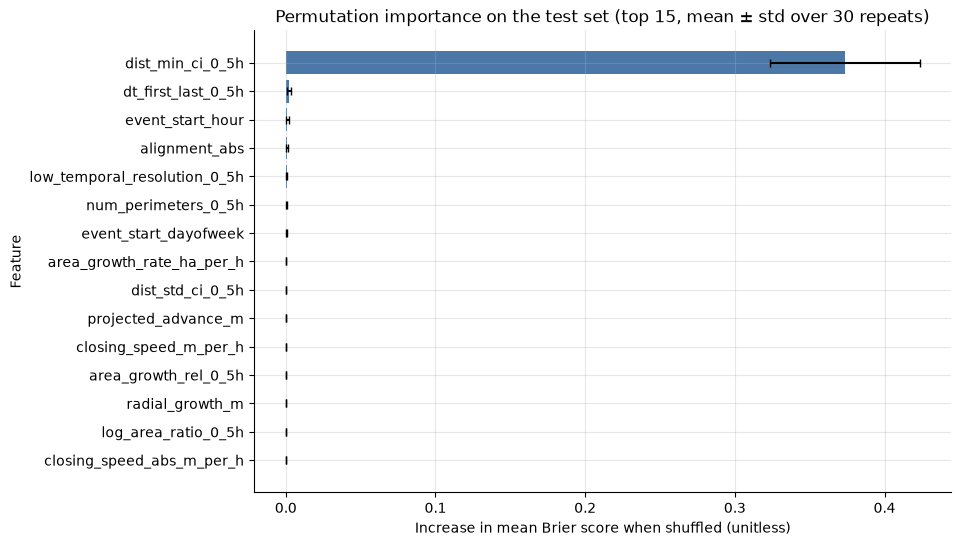

,importance,std
dist_min_ci_0_5h,0.3735,0.0499
dt_first_last_0_5h,0.0021,0.0015
event_start_hour,0.0011,0.0008
alignment_abs,0.0008,0.0006
low_temporal_resolution_0_5h,0.0006,0.0004
num_perimeters_0_5h,0.0004,0.0004
event_start_dayofweek,0.0002,0.0004
area_growth_rate_ha_per_h,0.0000,0.0000
dist_change_ci_0_5h,0.0000,0.0000
closing_speed_abs_m_per_h,0.0000,0.0000


In [8]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pi = permutation_importance(model, X_test, y_test, scoring=neg_mean_brier, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("importance")
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["importance"], xerr=top["std"], color="#4C78A8", capsize=3)
ax.set_xlabel("Increase in mean Brier score when shuffled (unitless)"); ax.set_ylabel("Feature")
ax.set_title("Permutation importance on the test set (top 15, mean ± std over 30 repeats)")
save(fig, "03_permutation_importance"); plt.show()
imp.sort_values("importance", ascending=False).head(10).round(4)

## 5. Risk bands
Predictions are grouped into **Low (0–25%)**, **Medium (25–50%)**, **High (50–75%)** and **Critical (75–100%)**. For each band and horizon we show how many test fires fall in it, the observed hit rate, and the band's *accuracy*: the share of its fires whose outcome matches the band's side of 50% (a hit for High/Critical, no hit for Low/Medium).

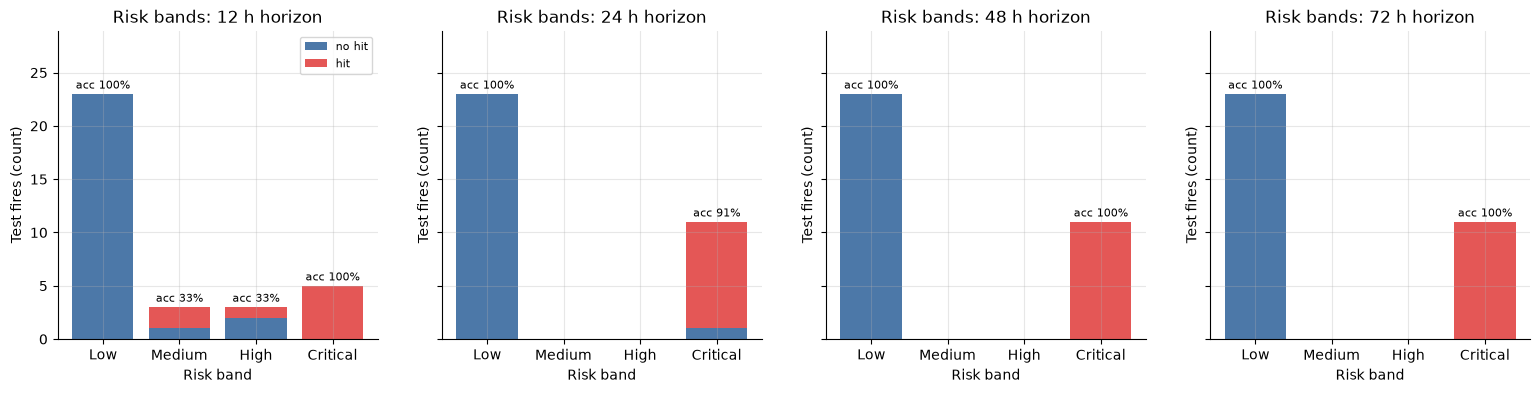

,horizon,band,fires,mean_pred_%,observed_hit_%,band_accuracy_%
0,12h,Low,23,0.2,0.0,100.0
1,12h,Medium,3,45.9,66.7,33.3
2,12h,High,3,63.6,33.3,33.3
3,12h,Critical,5,90.6,100.0,100.0
4,24h,Low,23,0.2,0.0,100.0
5,24h,Medium,0,NaN,NaN,NaN
6,24h,High,0,NaN,NaN,NaN
7,24h,Critical,11,94.6,90.9,90.9
8,48h,Low,23,0.2,0.0,100.0
9,48h,Medium,0,NaN,NaN,NaN


In [9]:
band_rows = []
for h in HORIZONS:
    bands = risk_band(P[f"p_{h}h"] * 100)
    y = Y[f"hit_{h}h"]
    for b, _, _ in RISK_BANDS:
        m = (bands == b).to_numpy()
        pred_hit = b in ("High", "Critical")
        band_rows.append({"horizon": f"{h}h", "band": b, "fires": int(m.sum()),
                          "mean_pred_%": P.loc[m, f"p_{h}h"].mean() * 100 if m.any() else np.nan,
                          "observed_hit_%": y[m].mean() * 100 if m.any() else np.nan,
                          "band_accuracy_%": ((y[m] == int(pred_hit)).mean() * 100) if m.any() else np.nan})
band_table = pd.DataFrame(band_rows)

fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
for ax, h in zip(axes, HORIZONS):
    t = band_table[band_table.horizon == f"{h}h"].set_index("band")
    bands = risk_band(P[f"p_{h}h"] * 100); y = Y[f"hit_{h}h"]
    hit_n = [int(((bands == b).to_numpy() & (y == 1).to_numpy()).sum()) for b in t.index]
    miss_n = [int(t.loc[b, "fires"]) - hit_n[i] for i, b in enumerate(t.index)]
    ax.bar(t.index, miss_n, color="#4C78A8", label="no hit"); ax.bar(t.index, hit_n, bottom=miss_n, color="#E45756", label="hit")
    for i, b in enumerate(t.index):
        if t.loc[b, "fires"]: ax.text(i, t.loc[b, "fires"] + .5, f"acc {t.loc[b, 'band_accuracy_%']:.0f}%", ha="center", fontsize=8)
    ax.set_ylim(0, len(test) * 0.85); ax.set_title(f"Risk bands: {h} h horizon"); ax.set_xlabel("Risk band"); ax.set_ylabel("Test fires (count)")
axes[0].legend(fontsize=8)
save(fig, "03_risk_bands"); plt.show()
band_table.round(1)

Most fires land in **Low** or **Critical**, which shows how sharply the 5 km distance signal separates them. The Medium and High bands hold the genuinely uncertain cases, mostly fires inside the radius where the question is *when* rather than *whether*.

## 6. Test on new data with `src/predict.py`
We create `data/test/sample_input.csv` from 8 fires (4 within 10 km of an evacuation zone and 4 farther away) of the **unlabelled competition file** (`data/raw/test.csv`). These are real new fires with no target, and none of them were used for training. We then run the CLI exactly as a user would.

In [10]:
new = pd.read_csv(DATA_DIR / "raw" / "test.csv")
# 4 fires near an evacuation zone (<= 10 km) + 4 farther away, so the demo covers the whole risk range
near = new[new["dist_min_ci_0_5h"] <= 10_000].sample(4, random_state=RANDOM_STATE)
far = new[new["dist_min_ci_0_5h"] > 10_000].sample(4, random_state=RANDOM_STATE)
sample = pd.concat([near, far]).reset_index(drop=True)
assert not set(TARGET_COLS) & set(sample.columns)
sample.to_csv(DATA_DIR / "test" / "sample_input.csv", index=False)

cmd = [sys.executable, "src/predict.py", "--input", "data/test/sample_input.csv", "--output", "data/test/sample_predictions.csv"]
print("$ uv run python " + " ".join(cmd[1:]))
r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True); print(r.stdout or r.stderr)
assert r.returncode == 0
pred = pd.read_csv(DATA_DIR / "test" / "sample_predictions.csv")
pred[[ID_COL, "dist_min_ci_0_5h", "num_perimeters_0_5h"] + [f"risk_{h}h_pct" for h in HORIZONS] + ["risk_percentage", "risk_band"]]

$ uv run python src/predict.py --input data/test/sample_input.csv --output data/test/sample_predictions.csv


Wrote 8 predictions to data/test/sample_predictions.csv
 event_id  risk_percentage risk_band
 78227688             0.44       Low
 49502022             0.20       Low
 70283101           100.00  Critical
 50233410           100.00  Critical
 98446281             0.00       Low
 91234126             0.77       Low
 10662602             0.00       Low
 78173856             0.00       Low



,event_id,dist_min_ci_0_5h,num_perimeters_0_5h,risk_12h_pct,risk_24h_pct,risk_48h_pct,risk_72h_pct,risk_percentage,risk_band
0,78227688,5787.125811,1,0.44,0.44,0.44,0.44,0.44,Low
1,49502022,9816.867561,1,0.20,0.20,0.20,0.20,0.20,Low
2,70283101,1159.411207,2,52.64,60.85,66.18,100.00,100.00,Critical
3,50233410,4012.556331,1,81.18,96.86,100.00,100.00,100.00,Critical
4,98446281,102921.525969,2,0.00,0.00,0.00,0.00,0.00,Low
5,91234126,17895.570375,7,0.49,0.77,0.77,0.77,0.77,Low
6,10662602,116941.044708,1,0.00,0.00,0.00,0.00,0.00,Low
7,78173856,162285.394820,1,0.00,0.00,0.00,0.00,0.00,Low


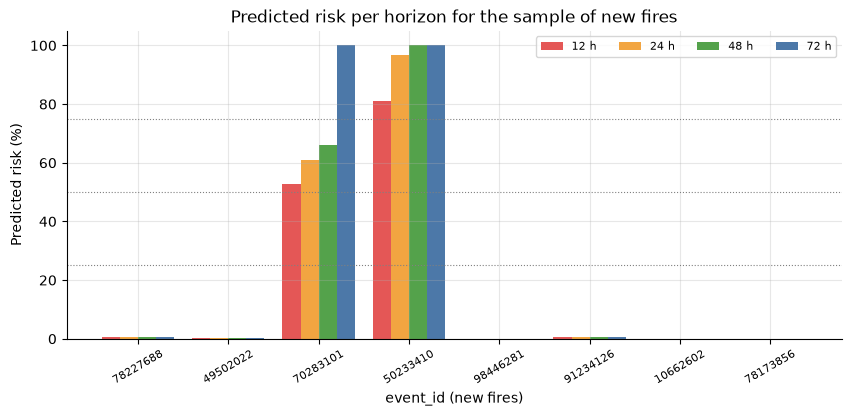

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(pred)); w = 0.2
for i, h in enumerate(HORIZONS):
    ax.bar(x + (i - 1.5) * w, pred[f"risk_{h}h_pct"], width=w, color=H_COLORS[h], label=f"{h} h")
for y0 in (25, 50, 75): ax.axhline(y0, color="grey", ls=":", lw=.8)
ax.set_xticks(x, pred[ID_COL].astype(str), rotation=30, fontsize=8)
ax.set_xlabel("event_id (new fires)"); ax.set_ylabel("Predicted risk (%)"); ax.set_ylim(0, 105)
ax.set_title("Predicted risk per horizon for the sample of new fires"); ax.legend(fontsize=8, ncol=4)
save(fig, "03_sample_predictions"); plt.show()

We also score all 95 competition fires and write a submission file in the format of `sample_submission.csv`.

In [12]:
cmd = [sys.executable, "src/predict.py", "--input", "data/raw/test.csv", "--output", "reports/test_predictions.csv", "--submission", "reports/submission.csv"]
r = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True); assert r.returncode == 0, r.stderr
sub = pd.read_csv(REPORT_DIR / "submission.csv")
template = pd.read_csv(DATA_DIR / "raw" / "sample_submission.csv")
assert list(sub.columns) == list(template.columns) and set(sub[ID_COL]) == set(template[ID_COL])
print("submission OK:", sub.shape)
print(pd.read_csv(REPORT_DIR / "test_predictions.csv")["risk_band"].value_counts().reindex([b for b, _, _ in RISK_BANDS]).fillna(0).astype(int).to_string())

submission OK: (95, 5)
risk_band
Low         67
Medium       0
High         0
Critical    28


## 7. Evaluation Summary
**Final model:** a tuned Random Forest per horizon (500 trees, `max_features=0.5`, `min_samples_leaf=3`) inside `FeatureEngineer → ColumnTransformer → classifier`, with probabilities forced to be non-decreasing across horizons.

| Horizon | ROC-AUC (test) | 95% CI | PR-AUC | Brier | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 12 h | 0.966 | 0.89–1.00 | 0.907 | 0.057 | 0.882 | 0.750 | 0.750 | 0.750 |
| 24 h | 0.971 | 0.89–1.00 | 0.906 | 0.030 | 0.971 | 0.909 | 1.000 | 0.952 |
| 48 h | 1.000 | 1.00–1.00 | 1.000 | 0.002 | 1.000 | 1.000 | 1.000 | 1.000 |
| 72 h | 1.000 | 1.00–1.00 | 1.000 | 0.000 | 1.000 | 1.000 | 1.000 | 1.000 |
| **Overall** | mean AUC **0.984** | | | mean Brier **0.022** | | | C-index **0.933** | |

Test results agree with the 5-fold CV estimates (mean Brier 0.021, AUC 0.993, C-index 0.952), so there is no sign of overfitting the model selection.

**Strengths**
- **Well calibrated:** both the test and the out-of-fold reliability curves sit on the diagonal, so a predicted 40% really means about 40%.
- **Near-perfect at separating fires that will hit from those that won't** (48–72 h), and good at 12–24 h.
- **Simple and robust:** one pipeline object handles imputation, scaling and feature engineering, and the CLI scores new CSVs in one command.

**Weaknesses**
- **Timing is the weak spot.** Among fires that *do* hit, telling early (≤ 12 h) from late hits gives an AUC of only about **0.80 out-of-fold** (0.71 on the 11 test hits). The 12 h band chart shows this: the Medium and High bands are only 33% accurate.
- **The model leans almost entirely on one feature.** Permutation importance is dominated by `dist_min_ci_0_5h` (0.37, more than 100× the next feature). It is close to a learned "distance < 5 km" rule plus a timing adjustment.
- **Probabilities are extreme.** Most fires get about 0% or about 100%. Predicting exactly 0% for a far-away fire is overconfident in a safety setting, so a small floor (e.g. 1%) would be prudent in operations.

**Limitations of the data**
- **Only 221 labelled fires** (34 for testing). The confidence intervals at 12 and 24 h are wide, and a few fires can move every metric.
- **The perfect 5 km separation is unlikely to hold perfectly elsewhere.** A fire just outside 5 km that grows fast could still hit, and none of the training fires show that.
- **Most fires (73%) have only one perimeter**, so growth and speed features are mostly zero and add little.
- **Possible selection bias:** closely monitored fires (many perimeters) hit more often.
- **No weather, wind, fuel or terrain data.** These drive real fire timing and are the obvious next step.